**Dataset:** [Ultralytics Depth8](https://github.com/ultralytics/ultralytics/blob/main/docs/en/datasets/depth/depth8.md)  
**Description:** Ultralytics Depth8 dataset, a compact set of 8 indoor RGB-D images for testing monocular depth estimation models and training pipelines

In [ ]:
import os
import cv2
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
import torch.nn.functional as F
from transformers import AutoImageProcessor, AutoModelForDepthEstimation

In [ ]:
# Load Depth Anything V2 Small

model_name = "depth-anything/Depth-Anything-V2-Small-hf"

processor = AutoImageProcessor.from_pretrained(model_name)
model = AutoModelForDepthEstimation.from_pretrained(model_name)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)
model.eval()

print("Device:", device)
print("Model:", model_name)

preprocessor_config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

Device: cpu
Model: depth-anything/Depth-Anything-V2-Small-hf


Image path: /content/drive/MyDrive/Computer Vision/05/Depth8_8pairs/image_08.png
Image size: (730, 530)


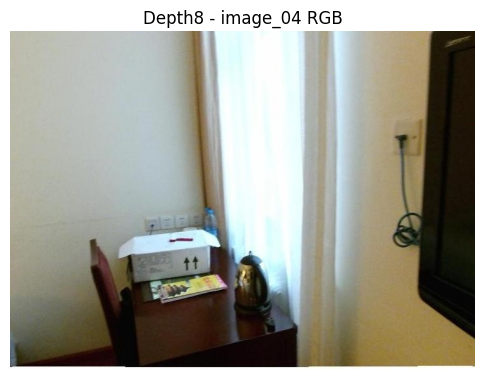

Depth shape: (530, 730)
Depth dtype: float32
Min depth: 0.23760426
Max depth: 8.29585
Mean depth: 2.6467764


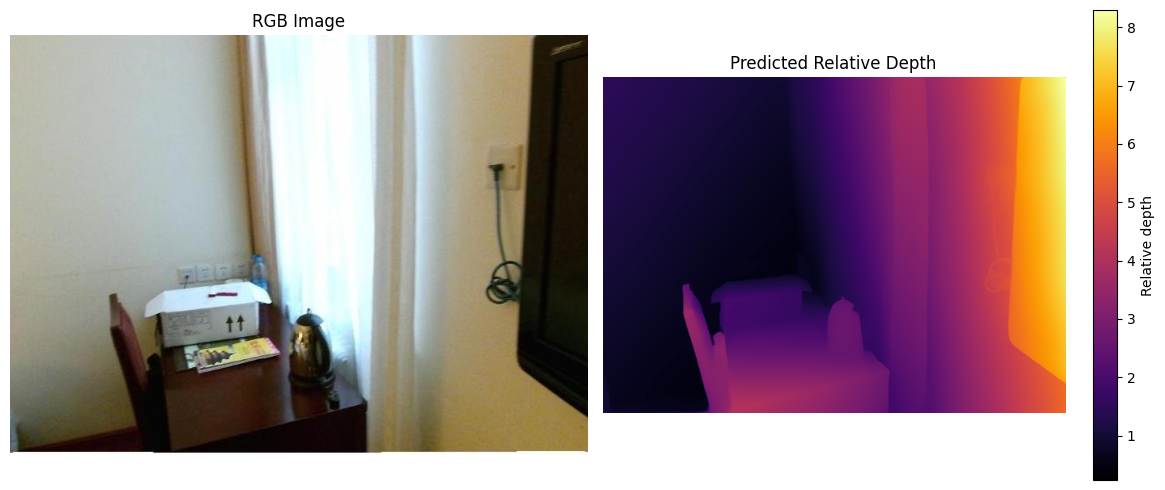

In [ ]:
# Load image_08 and run Depth Anything


# -----------------------------
# Paths
# -----------------------------

dataset_path = "/content/drive/MyDrive/Computer Vision/05/Depth8_8pairs"

image_path = os.path.join(
    dataset_path,
    "image_08.png"
)

print("Image path:", image_path)


# -----------------------------
# Load RGB image
# -----------------------------

image = Image.open(image_path).convert("RGB")

print("Image size:", image.size)


plt.figure(figsize=(6,5))
plt.imshow(image)
plt.title("Depth8 - image_08 RGB")
plt.axis("off")
plt.show()


# -----------------------------
# Depth Anything inference
# -----------------------------

inputs = processor(
    images=image,
    return_tensors="pt"
)

inputs = {
    k: v.to(device)
    for k, v in inputs.items()
}


with torch.no_grad():
    outputs = model(**inputs)


predicted_depth = outputs.predicted_depth


# -----------------------------
# Resize depth to original size
# -----------------------------

depth = predicted_depth.unsqueeze(1)

depth = F.interpolate(
    depth,
    size=image.size[::-1],
    mode="bicubic",
    align_corners=False
)

depth = depth.squeeze().cpu().numpy()


print("Depth shape:", depth.shape)
print("Depth dtype:", depth.dtype)
print("Min depth:", depth.min())
print("Max depth:", depth.max())
print("Mean depth:", depth.mean())


# -----------------------------
# Visualize RGB and depth
# -----------------------------

plt.figure(figsize=(12,5))


plt.subplot(1,2,1)
plt.imshow(image)
plt.title("RGB Image")
plt.axis("off")


plt.subplot(1,2,2)
plt.imshow(depth, cmap="inferno")
plt.title("Predicted Relative Depth")
plt.colorbar(label="Relative depth")
plt.axis("off")


plt.tight_layout()
plt.show()

Identifing three objects and define their ROIs (bounding boxes).

For an ROI (bounding box), the coordinates are defined as:

(x1, y1, x2, y2)

where:

* (x1, y1) = the top-left corner of the bounding box
* (x2, y2) = the bottom-right corner of the bounding box

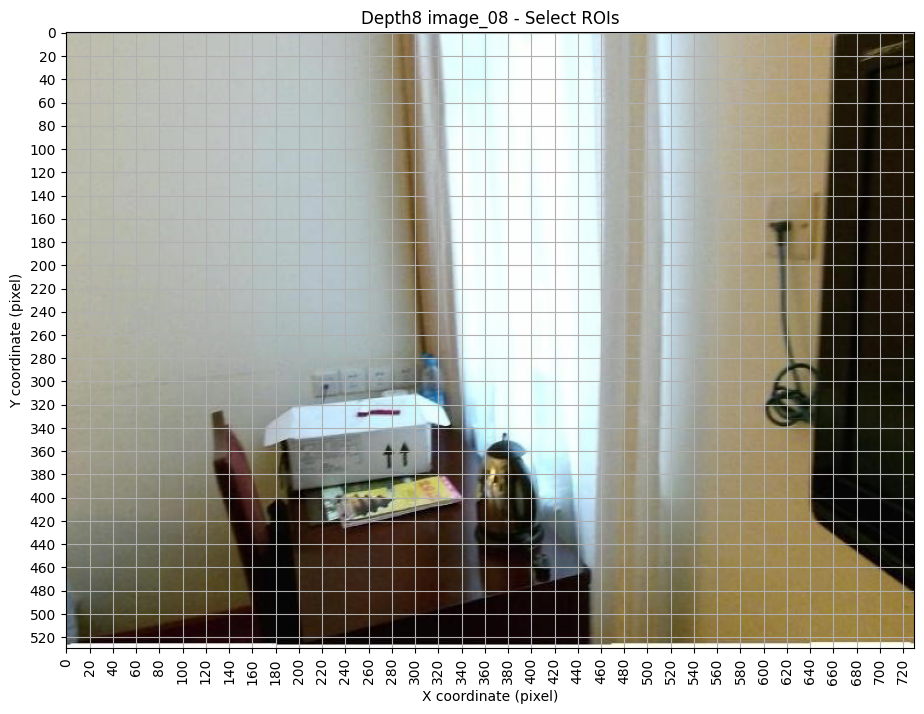

In [ ]:
# Load image_08

image_path = os.path.join(
    dataset_path,
    "image_08.png"
)

image_08 = Image.open(image_path).convert("RGB")

img_array = np.array(image_08)


# Display with coordinates

plt.figure(figsize=(12,8))

plt.imshow(img_array)

plt.title("Depth8 image_08 - Select ROIs")
# X-axis ticks every 20 pixels
plt.xticks(
    np.arange(0, 731, 20),
    rotation=90
)

# Y-axis ticks every 20 pixels
plt.yticks(
    np.arange(0, 531, 20)
)

plt.grid()

plt.xlabel("X coordinate (pixel)")
plt.ylabel("Y coordinate (pixel)")

plt.show()

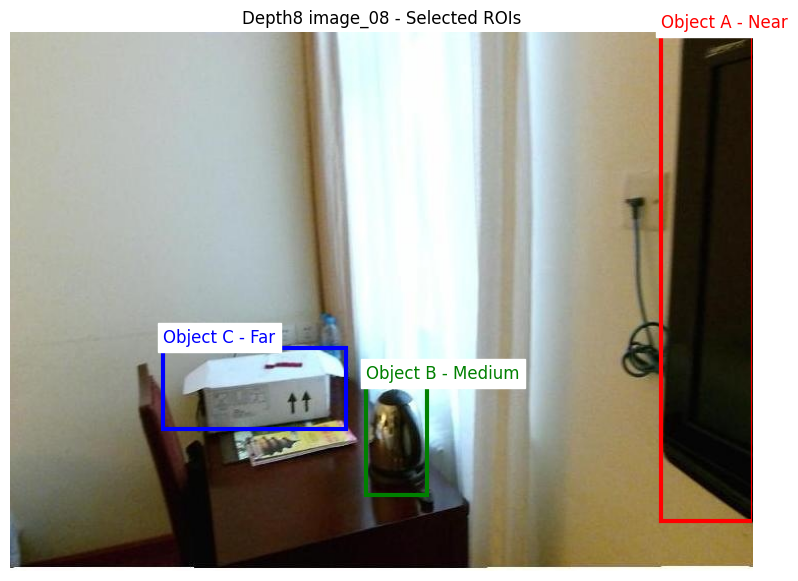

In [ ]:
# Visually verifing the ROIs


# Convert image to numpy array
image_array = np.array(image_08)


# Define ROIs
rois = {
    "Object A - Near": (640, 0, 730, 480),
    "Object B - Medium": (350, 345, 410, 455),
    "Object C - Far": (150, 310, 330, 390)
}


# Colors for visualization
colors = {
    "Object A - Near": "red",
    "Object B - Medium": "green",
    "Object C - Far": "blue"
}


# Plot image
fig, ax = plt.subplots(figsize=(10,7))

ax.imshow(image_array)


# Draw rectangles and labels
for name, (x1, y1, x2, y2) in rois.items():

    width = x2 - x1
    height = y2 - y1

    rect = patches.Rectangle(
        (x1, y1),
        width,
        height,
        linewidth=3,
        edgecolor=colors[name],
        facecolor='none'
    )

    ax.add_patch(rect)

    ax.text(
        x1,
        y1 - 5,
        name,
        color=colors[name],
        fontsize=12,
        backgroundcolor="white"
    )


ax.set_title("Depth8 image_08 - Selected ROIs")
ax.axis("off")

plt.show()

These ROIs are well separated :

* Object A (Near): right side of the image, large region close to the camera
* Object B (Medium): middle area
* Object C (Far): background region

In [ ]:
# Calculate the depth statistics for each ROI


# -----------------------------
# Define ROIs
# -----------------------------

rois = {
    "Object A - Near": (640, 0, 730, 480),
    "Object B - Medium": (350, 345, 410, 455),
    "Object C - Far": (150, 310, 330, 390)
}


# -----------------------------
# Calculate depth statistics
# -----------------------------

results = []

for name, (x1, y1, x2, y2) in rois.items():

    roi_depth = depth[y1:y2, x1:x2]

    results.append({
        "Object": name,
        "Mean Depth": np.mean(roi_depth),
        "Median Depth": np.median(roi_depth),
        "Minimum Depth": np.min(roi_depth),
        "Maximum Depth": np.max(roi_depth)
    })


# Convert to dataframe

depth_results = pd.DataFrame(results)

depth_results

,Object,Mean Depth,Median Depth,Minimum Depth,Maximum Depth
0,Object A - Near,6.635872,6.738457,4.340816,8.295850
1,Object B - Medium,2.327538,2.549384,0.885596,2.809279
2,Object C - Far,1.340447,1.521060,0.472287,2.989030


## Compare with ground truth

In [ ]:
# Load the ground truth depth

gt_depth_path = os.path.join(
    dataset_path,
    "depth_08.npy"
)

gt_depth = np.load(gt_depth_path)

print("GT depth shape:", gt_depth.shape)
print("GT dtype:", gt_depth.dtype)

print("Min:", gt_depth.min())
print("Max:", gt_depth.max())
print("Mean:", gt_depth.mean())

GT depth shape: (530, 730)
GT dtype: float32
Min: 0.561
Max: 2.391
Mean: 1.4861431


In [ ]:
# Calculate GT depth statistics for the same ROIs

gt_results = []

for name, (x1, y1, x2, y2) in rois.items():

    roi_gt = gt_depth[y1:y2, x1:x2]

    # Remove invalid depth pixels (0 means no measurement)
    roi_gt = roi_gt[roi_gt > 0]

    gt_results.append({
        "Object": name,
        "Mean GT Depth (m)": np.mean(roi_gt),
        "Median GT Depth (m)": np.median(roi_gt),
        "Minimum GT Depth (m)": np.min(roi_gt),
        "Maximum GT Depth (m)": np.max(roi_gt)
    })


gt_table = pd.DataFrame(gt_results)

gt_table

,Object,Mean GT Depth (m),Median GT Depth (m),Minimum GT Depth (m),Maximum GT Depth (m)
0,Object A - Near,0.751062,0.755,0.561,1.049
1,Object B - Medium,1.472942,1.393,1.236,2.319
2,Object C - Far,1.842006,1.709,1.451,2.341


The ground truth depth confirms the physical distances:

* Object A has the smallest metric depth (0.75 m), therefore it is the nearest object.
* Object B is farther (1.47 m).
* Object C has the largest metric depth (1.84 m), therefore it is the farthest object.